# 🎓 Exposé — Deep Learning : prédire le diabète avec un modele

**Présenté par :** *ZONGO P Juste Landry* 


## Partie 0 : le matériel

On importe les outils. Rien à comprendre en détail ici :
- `pandas` lit les tableaux, `numpy` fait des calculs sur des nombres, `matplotlib` dessine ;
- `scikit-learn` prépare les données et donne des modèles simples ;
- `keras` (dans TensorFlow) construit les réseaux de neurones.

In [5]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # masque les warnings TensorFlow (GPU etc.)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras

# On fixe le hasard pour retrouver les mêmes résultats à chaque lancement
keras.utils.set_random_seed(42)
print("Tout est prêt")

Tout est prêt


## Partie 1 : découvrir les données

### 🎯 Objectif
Comprendre ce que le modèle va regarder, avant de construire quoi que ce soit.

Le fichier est un tableau. **Chaque ligne est une personne.** Chaque colonne est une **mesure** (le mot technique est *caractéristique*, ou *feature*) :

| Colonne | Signification |
|---|---|
| Pregnancies | nombre de grossesses |
| Glucose | taux de sucre dans le sang |
| BloodPressure | tension artérielle |
| SkinThickness | épaisseur de la peau |
| Insulin | taux d'insuline |
| BMI | IMC (rapport poids/taille) |
| DiabetesPedigreeFunction | indice d'antécédents familiaux |
| Age | âge |
| **Outcome** | **la réponse : 1 = diabète, 0 = pas de diabète** |

Le modèle doit **deviner `Outcome` à partir des 8 autres colonnes**.

In [6]:
data = pd.read_csv("diabetes.csv")

print("Taille du tableau (lignes, colonnes) :", data.shape)
data.head()

Taille du tableau (lignes, colonnes) : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
# Statistiques de chaque colonne : moyenne, minimum, maximum...
data.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [8]:
# Combien de personnes avec / sans diabète ?
print(data["Outcome"].value_counts())
print()
print((data["Outcome"].value_counts(normalize=True) * 100).round())

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    65.0
1    35.0
Name: proportion, dtype: float64


In [9]:
colonnes_suspectes = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in colonnes_suspectes:
    print(f"{col:15s} -> {(data[col] == 0).sum()} zéros")

Glucose         -> 5 zéros
BloodPressure   -> 35 zéros
SkinThickness   -> 227 zéros
Insulin         -> 374 zéros
BMI             -> 11 zéros


## Partie 2 : séparer apprentissage et test

### 🎯 Objectif
Garder des personnes **cachées** pour juger le modèle honnêtement.


- `X` = les 8 mesures (ce que le modèle regarde).
- `y` = la réponse (ce qu'il doit deviner).
- On donne **80 %** des personnes au modèle pour apprendre, et on garde **20 %** cachées pour l'examen final.

In [10]:
X = data.drop("Outcome", axis=1)   # les mesures
y = data["Outcome"]                # la réponse

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Pour apprendre :", len(X_train), "personnes")
print("Pour le test   :", len(X_test), "personnes")

Pour apprendre : 614 personnes
Pour le test   : 154 personnes


## Partie 3 : mettre à la même échelle

### 🎯 Objectif
Éviter que le modèle croie qu'une mesure est plus importante juste parce que ses chiffres sont plus grands.

L'âge va de 21 à 81, mais l'insuline monte jusqu'à plus de 800. Sans correction, l'insuline écraserait tout le reste. `StandardScaler` transforme chaque colonne pour qu'elle ait une **moyenne de 0** et une dispersion comparable.


In [11]:
print("AVANT (premières lignes d'apprentissage) :")
display(X_train.head(3).round(2))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("APRÈS (mêmes personnes, mises à l'échelle) :")
display(pd.DataFrame(X_train[:3], columns=X.columns).round(2))

AVANT (premières lignes d'apprentissage) :


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,2,84,0,0,0,0.0,0.30,21
618,9,112,82,24,0,28.2,1.28,50
346,1,139,46,19,83,28.7,0.65,22


APRÈS (mêmes personnes, mises à l'échelle) :


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.53,-1.15,-3.75,-1.32,-0.70,-4.14,-0.49,-1.04
1,1.59,-0.28,0.68,0.23,-0.70,-0.49,2.42,1.49
2,-0.83,0.57,-1.27,-0.09,0.01,-0.42,0.55,-0.95


In [12]:
# Vérification : après mise à l'échelle, chaque colonne a une moyenne ~0 et un écart ~1
print("Moyennes :", X_train.mean(axis=0).round(2))
print("Écarts   :", X_train.std(axis=0).round(2))

Moyennes : [ 0. -0.  0.  0. -0. -0.  0. -0.]
Écarts   : [1. 1. 1. 1. 1. 1. 1. 1.]


## Partie 4 : un neurone, puis le réseau

### 🎯 Objectif
Voir qu'un neurone n'est qu'un petit calcul, et qu'un **poids** n'est qu'un nombre.

### 📖 Explication
Un neurone fait quatre choses :
1. il prend des nombres en entrée ;
2. il multiplie chacun par son **poids** (à quel point cette mesure compte) ;
3. il additionne tout, puis ajoute un **biais** (un petit réglage de départ) ;
4. il applique un filtre, ici **ReLU** : si le résultat est négatif, il devient 0, sinon il reste tel quel.


### 📖 Le réseau de neurone

Un réseau de neurones, c'est **plusieurs neurones côte à côte (une couche), et plusieurs couches l'une après l'autre** :

- **Entrée : 8** (une par mesure). Imposé par les données.
- **Couche cachée 1 : 16 neurones.** Chacun cherche un petit motif.
- **Couche cachée 2 : 8 neurones.** Elle combine les motifs.
- **Sortie : 1 neurone** avec **sigmoïde**, qui écrase le résultat entre 0 et 1 (le risque).

Seules les couches cachées (16 et 8) sont un **choix libre** : on les teste dans la partie 7.

In [13]:
model = keras.Sequential([
    keras.Input(shape=(8,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Dans le tableau, la colonne **Param #** compte les poids et biais. Vérifions à la main :
- couche 1 : 8 × 16 poids + 16 biais = **144**
- couche 2 : 16 × 8 poids + 8 biais = **136**
- couche 3 : 8 × 1 poids + 1 biais = **9**
- total : **289**

## Partie 5 : entraîner

### 🎯 Objectif
Comprendre ce que font `compile` et `fit`.

**`compile`** : on choisit trois choses.
- **loss** (`binary_crossentropy`) : comment mesurer l'erreur. Dire 0,9 quand la vérité est 0 donne une grosse erreur.
- **optimizer** (`adam`) : la méthode pour corriger les poids. Imagine quelqu'un qui descend une montagne dans le brouillard : il sent la pente et fait un petit pas vers le bas. L'erreur est l'altitude, la vallée est le meilleur réglage.
- **metrics** (`accuracy`) : le pourcentage de bonnes réponses, pour nous suivre.

**`fit`** : le modèle regarde les personnes par paquets de 32, mesure son erreur, ajuste ses poids, et passe au paquet suivant. Quand il a vu toutes les personnes une fois, c'est **un epoch**. On en fait 50.

`validation_split=0.2` met de côté 20 % de l'apprentissage pour une **mini-vérification à chaque epoch** (`val_accuracy`, `val_loss`). Elle permet de voir si le modèle comprend vraiment ou récite par cœur.

In [14]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

historique = model.fit(
    X_train, y_train,
    epochs=50,
    validation_split=0.2,
    verbose=0,          # on cache les 50 lignes, on regardera les courbes
)
print("Entraînement terminé")

Entraînement terminé


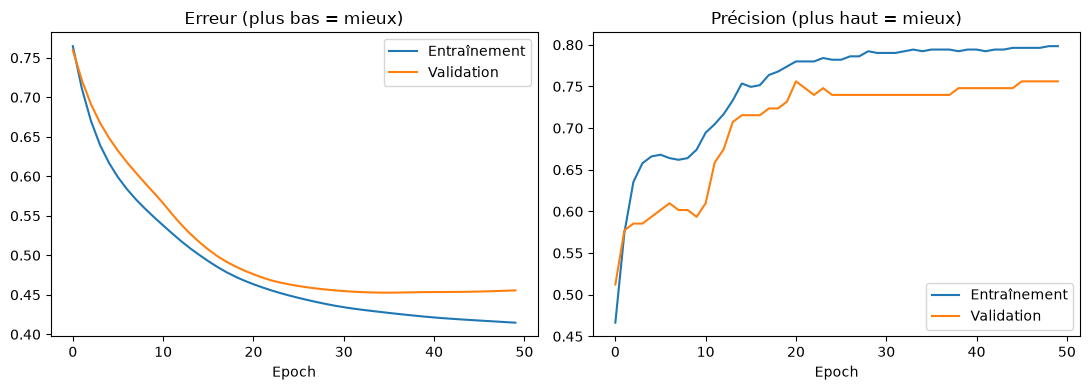

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(historique.history["loss"], label="Entraînement")
ax1.plot(historique.history["val_loss"], label="Validation")
ax1.set_title("Erreur (plus bas = mieux)")
ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(historique.history["accuracy"], label="Entraînement")
ax2.plot(historique.history["val_accuracy"], label="Validation")
ax2.set_title("Précision (plus haut = mieux)")
ax2.set_xlabel("Epoch"); ax2.legend()

plt.tight_layout()
plt.show()


- Au début, la précision est proche de 50 % : c'est le **hasard** (poids aléatoires).
- Elle monte, puis **se stabilise**. Après ce point, les epochs en plus n'apportent presque rien.
- Si la courbe d'entraînement continue de monter alors que celle de validation stagne ou descend, c'est le signe du **surapprentissage** : le modèle apprend les exemples par cœur.

Si ton score d'entraînement est de 99 % mais celui de validation de 60 %, que s'est-il passé ? Comment s'appelle ce problème ?

Le modèle a fait du **surapprentissage** (*overfitting*) : il a appris les exemples d'entraînement **par cœur** au lieu de comprendre. Il réussit donc très bien sur les personnes qu'il connaît (99 %) mais échoue sur les nouvelles (60 %). On le repère quand l'erreur d'entraînement continue de baisser pendant que celle de validation remonte.

## Partie 6 : tester honnêtement

### 🎯 Objectif
Juger le modèle sur les personnes cachées, et comprendre **quels types d'erreurs** il fait.

`evaluate` donne le score final sur les 20 % jamais vus. C'est le chiffre à présenter.
Mais une seule précision cache une chose importante : **toutes les erreurs ne se valent pas** en santé.
- **Faux négatif** : le modèle dit « pas de diabète » à quelqu'un qui en a. **C'est le plus grave**, la personne n'est pas soignée.
- **Faux positif** : le modèle dit « diabète » à quelqu'un qui n'en a pas. Gênant, mais un examen le corrigera.

La **matrice de confusion** compte ces cas.

In [16]:
perte, precision = model.evaluate(X_test, y_test, verbose=0)
print(f"Précision sur le test : {precision:.3f}  ({precision*100:.1f} %)")

Précision sur le test : 0.760  (76.0 %)


In [ ]:
# Le modèle donne un risque entre 0 et 1. On décide : risque > SEUIL => "diabète"
SEUIL = 0.5

risques = model.predict(X_test, verbose=0).ravel()
predictions = (risques > SEUIL).astype(int)

cm = confusion_matrix(y_test, predictions)
print(f"Seuil utilisé : {SEUIL}")
print("                    Prédit : sain   Prédit : diabète")
print(f"Vraiment sain       {cm[0,0]:12d}   {cm[0,1]:16d}")
print(f"Vraiment diabète    {cm[1,0]:12d}   {cm[1,1]:16d}")
print()
print(f"Faux négatifs (les plus graves) : {cm[1,0]}")
print(f"Faux positifs                   : {cm[0,1]}")

Seuil utilisé : 0.5
                    Prédit : sain   Prédit : diabète
Vraiment sain                 80                 19
Vraiment diabète              18                 37

Faux négatifs (les plus graves) : 18
Faux positifs                   : 19


In [18]:
print(classification_report(y_test, predictions, target_names=["Sain", "Diabète"]))

              precision    recall  f1-score   support

        Sain       0.82      0.81      0.81        99
     Diabète       0.66      0.67      0.67        55

    accuracy                           0.76       154
   macro avg       0.74      0.74      0.74       154
weighted avg       0.76      0.76      0.76       154




- **precision** : parmi ceux que le modèle déclare malades, combien le sont vraiment ?
- **recall** (rappel) : parmi ceux qui sont vraiment malades, combien le modèle en trouve ? **C'est le chiffre à surveiller en santé.**


**1.** Une précision d'environ 75 % veut dire qu'environ 1 personne sur 4 est mal classée, ce qui est trop pour décider seul en santé. De plus, comme 65 % des personnes sont saines, un modèle qui répondrait toujours « pas de diabète » aurait déjà 65 %. Et la précision seule ne dit pas **quel type d'erreur** le modèle fait.

**2.** L'erreur la plus grave est le **faux négatif** : dire « pas de diabète » à quelqu'un qui en a. Cette personne ne serait pas soignée. Dans mon test, le modèle a manqué 18 malades sur 55. Un faux positif est moins grave, car un examen peut le corriger.

## Partie 7 : expériences sur le nombre de neurones


### 📖 Explication
Entrée (8) et sortie (1) sont imposées par les données. Les couches cachées sont **libres** : ce sont des **hyperparamètres** (des réglages qu'on fixe avant l'entraînement, contrairement aux poids que le modèle apprend).


In [19]:
def essayer(n_neurones, essais=3, epochs=50, n_couches=1):
    """Entraîne un réseau et renvoie (moyenne, écart) de la précision de validation."""
    scores = []
    for graine in range(essais):
        keras.utils.set_random_seed(graine)
        couches = [keras.Input(shape=(8,))]
        for _ in range(n_couches):                    # ✍️ essaie n_couches=2 !
            couches.append(keras.layers.Dense(n_neurones, activation="relu"))
        couches.append(keras.layers.Dense(1, activation="sigmoid"))
        m = keras.Sequential(couches)
        m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
        h = m.fit(X_train, y_train, epochs=epochs, validation_split=0.2, verbose=0)
        scores.append(h.history["val_accuracy"][-1])
    return np.mean(scores), np.std(scores)

resultats = []
for n in [2, 4, 8, 16, 32, 64]:
    moyenne, ecart = essayer(n)
    resultats.append({"neurones": n, "val_accuracy (moyenne)": round(moyenne, 3), "écart": round(ecart, 3)})
    print(f"{n:3d} neurones -> {moyenne:.3f} (± {ecart:.3f})")

pd.DataFrame(resultats)

  2 neurones -> 0.718 (± 0.038)
  4 neurones -> 0.732 (± 0.023)
  8 neurones -> 0.732 (± 0.018)
 16 neurones -> 0.748 (± 0.018)
 32 neurones -> 0.756 (± 0.000)
 64 neurones -> 0.748 (± 0.007)


,neurones,val_accuracy (moyenne),écart
0,2,0.718,0.038
1,4,0.732,0.023
2,8,0.732,0.018
3,16,0.748,0.018
4,32,0.756,0.000
5,64,0.748,0.007



- Si deux tailles sont séparées par **moins que l'écart** (le `±`), la différence n'est **pas réelle** : c'est du hasard.
- Très peu de neurones (2) peut *sous-apprendre* : le modèle est trop simple.
- Beaucoup de neurones (64) peut *surapprendre*, surtout avec peu de données (ici 768 personnes).

Il n'y a pas de formule, parce que le bon nombre dépend des données et du problème. L'entrée (8) et la sortie (1) sont imposées, mais pour les couches cachées on **essaie plusieurs tailles** (2, 4, 8, 16, 32, 64) et on **compare la précision de validation**, en répétant chaque essai plusieurs fois à cause du hasard. Dans mon test, les résultats vont de 71,8 % (2 neurones) à 75,6 % (32 neurones) : les écarts sont petits, donc la taille compte peu ici. On garde une taille qui marche bien sans être trop grande (16 ou 32), pour limiter le risque de surapprentissage.

## Partie 8 : sauvegarder et réutiliser le modèle

### 🎯 Objectif
Comprendre ce qu'**est** un modèle concrètement, et comment on l'utilise ailleurs.


Un modèle entraîné, c'est **deux choses dans un fichier** :
1. la **structure** (nombre de couches, de neurones, activations) ;
2. les **valeurs apprises** (les 289 poids et biais).

Il ne contient ni les données d'entraînement ni des règles écrites à la main.

Il faut **aussi sauvegarder le scaler** : toute nouvelle personne doit être mise à l'échelle **de la même façon** qu'à l'entraînement, sinon le modèle donne n'importe quoi.

| Format | Usage |
|---|---|
| `.keras` | format actuel de Keras (celui qu'on utilise) |
| `.h5` | ancien format de Keras |
| `.tflite` | version allégée pour **téléphone** (app Flutter) |
| `.onnx` | format universel pour d'autres outils |

In [22]:
import joblib

model.save("modele_diabete.keras")
joblib.dump(scaler, "scaler.pkl")
print("Fichiers enregistrés : modele_diabete.keras et scaler.pkl")

Fichiers enregistrés : modele_diabete.keras et scaler.pkl


Maintenant, simulons une **autre application** qui n'a jamais vu l'entraînement : elle charge les deux fichiers et prédit pour une nouvelle personne.

In [24]:
modele_charge = keras.models.load_model("modele_diabete.keras")
scaler_charge = joblib.load("scaler.pkl")

# Une personne : grossesses, glucose, tension, peau, insuline, IMC, antécédents, âge
nouvelle = pd.DataFrame([[2, 200, 70, 25, 100, 30.0, 0.5, 45]], columns=X.columns)

nouvelle_echelle = scaler_charge.transform(nouvelle)
risque = modele_charge.predict(nouvelle_echelle, verbose=0)[0][0]

print(f"Risque estimé : {risque*100:.0f} %")

Risque estimé : 80 %
